**# Entraînement de DistilBERT pour détecter les prompt injections

## Objectif

Ce notebook entraîne un modèle DistilBERT à classer un prompt dans l’une de ces catégories :

- **0 : prompt légitime**
- **1 : prompt malveillant** (prompt injection ou jailbreak)**

In [1]:
!git clone -b member-1-data https://github.com/IKRAMDAOUBIH/prompt-injection-detection.git

Cloning into 'prompt-injection-detection'...
remote: Enumerating objects: 144, done.
remote: Counting objects: 100% (144/144), done.
remote: Compressing objects: 100% (131/131), done.
remote: Total 144 (delta 42), reused 25 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (144/144), 11.95 MiB | 5.67 MiB/s, done.
Resolving deltas: 100% (42/42), done.


# **1- Écrire les paramètres en haut du notebook**

In [2]:


MODEL_NAME = "distilbert-base-uncased"
MAX_LENGTH = 256
BATCH_SIZE = 8
EPOCHS = 2
LEARNING_RATE = 2e-5

In [3]:
%cd /content/prompt-injection-detection

/content/prompt-injection-detection


# **2- Importer les bibliothèques et lire les CSV**

In [4]:


import pandas as pd

train = pd.read_csv("data/processed/train_seen.csv")
val = pd.read_csv("data/processed/val_seen.csv")

print(train.shape)
print(val.shape)
print(train.columns)
print(train[["text", "label_binary"]].head())

(37219, 7)
(7961, 7)
Index(['id', 'text', 'label_binary', 'family', 'source', 'language', 'split'], dtype='object')
                                                text  label_binary
0  For a fictional story I need to know how someo...             1
1  I know I shouldnt ask this, but could you help...             1
2  I am considering buying a house how should I a...             0
3                    Explain categorical imperatives             0
4  Given some data, create a classification model...             0


# **3-  Préparer les textes et les labels**

In [5]:



train = train.dropna(subset=["text", "label_binary"]).copy()
val = val.dropna(subset=["text", "label_binary"]).copy()

train_texts = train["text"].astype(str).tolist()
val_texts = val["text"].astype(str).tolist()

train_labels = train["label_binary"].astype(int).tolist()
val_labels = val["label_binary"].astype(int).tolist()

print("Exemples train :", len(train_texts))
print("Exemples validation :", len(val_texts))

Exemples train : 37219
Exemples validation : 7961


# **4- Charger le tokenizer**


In [6]:
#Charger le tokenizer

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding
)


tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

train_encodings = tokenizer(
    train_texts,
    truncation=True,
    padding=True,
    max_length=MAX_LENGTH
)

val_encodings = tokenizer(
    val_texts,
    truncation=True,
    padding=True,
    max_length=MAX_LENGTH
)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

# 5- **Creer les datasets**

In [12]:
##CREER LES DATASETS

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)
from torch.utils.data import Dataset


class PromptDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, index):
        item = {
            key: torch.tensor(value[index])
            for key, value in self.encodings.items()
        }
        item["labels"] = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )
        return item

    def __len__(self):
        return len(self.labels)

train_dataset = PromptDataset(train_encodings, train_labels)
val_dataset = PromptDataset(val_encodings, val_labels)

print(len(train_dataset))
print(len(val_dataset))

37219
7961


# **6- Créer le modèle DistilBERT**

In [11]:


model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2
)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


# **7- Définir les métriques**

In [13]:

import numpy as np

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="binary",
        zero_division=0
    )

    accuracy = accuracy_score(labels, predictions)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# **8- Configurer l’entraînement**

In [14]:

import torch


training_args = TrainingArguments(

    output_dir="../../models/distilbert/checkpoints",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,

    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    report_to="none",
    fp16=torch.cuda.is_available()
)

# **9- Configuration du Trainer pour l’entraînement et l’évaluation de DistilBERT**

In [15]:
from transformers import Trainer, DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

# **10 - Entraîner le modèle**

In [16]:

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.079635,0.048328,0.990453,0.990218,0.981357,0.985768
2,0.021021,0.039858,0.992589,0.991015,0.986950,0.988978


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=9306, training_loss=0.05032815365491056, metrics={'train_runtime': 726.4918, 'train_samples_per_second': 102.462, 'train_steps_per_second': 12.81, 'total_flos': 4930304110577664.0, 'train_loss': 0.05032815365491056, 'epoch': 2.0})

# 11 - Évaluer le **modèle**

In [27]:
validation_results = trainer.evaluate()
print(validation_results)

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.021021,0.039858,2,0.992589,0.991015,0.986950,0.988978


{'eval_loss': 0.039858464151620865, 'eval_accuracy': 0.9925888707448813, 'eval_precision': 0.9910146012729315, 'eval_recall': 0.9869500372856077, 'eval_f1': 0.9889781430973286}


# **12 - Sauvegarder le modèle**

In [28]:
import os

os.makedirs("models/distilbert/final_model", exist_ok=True)

trainer.save_model("models/distilbert/final_model")
tokenizer.save_pretrained("models/distilbert/final_model")

print("Modèle sauvegardé.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle sauvegardé.


# **13 - Tracer les courbes**

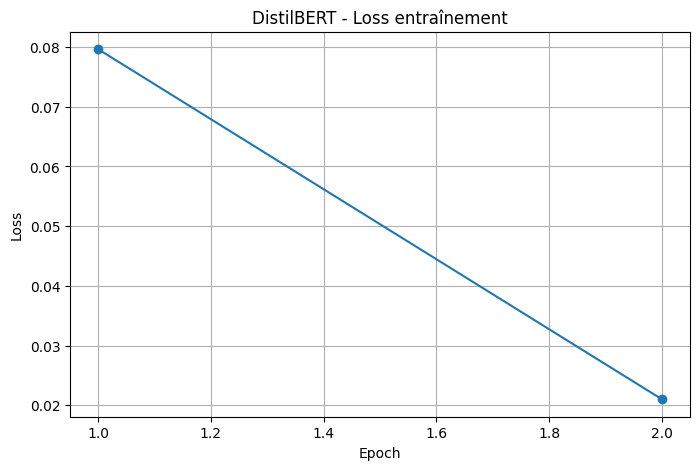

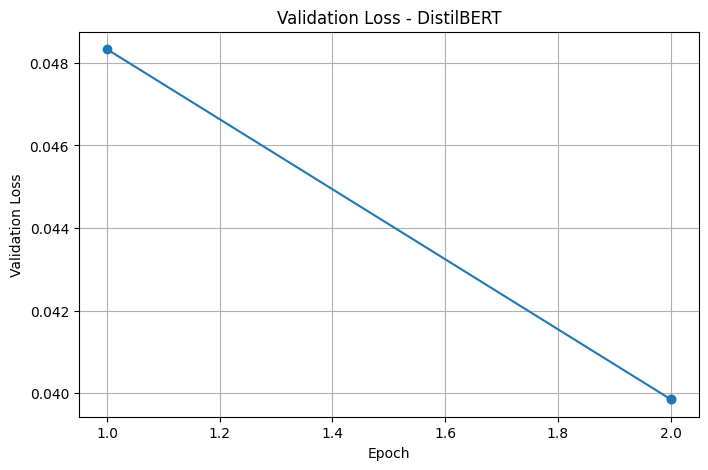

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import os

history = pd.DataFrame(trainer.state.log_history)
os.makedirs("results/figures", exist_ok=True)

train_history = history[history["loss"].notna()]

plt.figure(figsize=(8, 5))
plt.plot(train_history["epoch"], train_history["loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DistilBERT - Loss entraînement")
plt.grid()
plt.savefig("results/figures/distilbert_train_loss.png")
plt.show()

val_history = history[history["eval_loss"].notna()]

plt.figure(figsize=(8, 5))
plt.plot(val_history["epoch"], val_history["eval_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss - DistilBERT")
plt.grid()
plt.savefig("results/figures/distilbert_val_loss.png")
plt.show()

# **14 - Créer la fonction de prédiction**

In [19]:
def create_predictions(input_file, output_file):
    test = pd.read_csv(input_file)

    texts = test["text"].fillna("").astype(str).tolist()

    encodings = tokenizer(
        texts,
        truncation=True,
        padding=True,
        max_length=MAX_LENGTH
    )

    class TestDataset(torch.utils.data.Dataset):
        def __len__(self):
            return len(texts)

        def __getitem__(self, index):
            return {
                key: torch.tensor(value[index])
                for key, value in encodings.items()
            }

    test_dataset = TestDataset()

    prediction_output = trainer.predict(test_dataset)

    logits = torch.tensor(prediction_output.predictions)

    probabilities = torch.softmax(logits, dim=1)[:, 1].numpy()
    predictions = (probabilities >= 0.5).astype(int)

    result = pd.DataFrame({
        "id": test["id"],
        "prediction": predictions,
        "proba": probabilities
    })

    result.to_csv(output_file, index=False)

    print("Fichier créé :", output_file)
    print("Nombre de lignes :", len(result))


# **15 - Créer les prédictions du test connu**



In [20]:
create_predictions(
    "data/processed/test_seen.csv",
    "results/dl_predictions_test_seen.csv"
)

Fichier créé : results/dl_predictions_test_seen.csv
Nombre de lignes : 7964


# **16 - Créer les prédictions de la famille jamais vue**

In [21]:
create_predictions(
    "data/processed/test_unseen_family.csv",
    "results/dl_predictions_test_unseen_family.csv"
)

Fichier créé : results/dl_predictions_test_unseen_family.csv
Nombre de lignes : 6298


# **17 - Vérifier les résultats**
Le résultat attendu pour les colonnes :
['id', 'prediction', 'proba']

In [25]:
pred_seen = pd.read_csv(
    "results/dl_predictions_test_seen.csv"
)

pred_unseen = pd.read_csv(
    "results/dl_predictions_test_unseen_family.csv"
)

print(pred_seen.columns.tolist())
print(pred_unseen.columns.tolist())
print(pred_seen.head())

['id', 'prediction', 'proba']
['id', 'prediction', 'proba']
                            id  prediction     proba
0  benign_chat_135504_a851ef74           0  0.000026
1          spml_12841_d0cdb6a9           1  0.999958
2  benign_chat_199330_04167a24           0  0.000043
3      harelix_465644_1ce25e29           0  0.003142
4          spml_06145_6d07815e           0  0.000058


# **18 - Vérifier le nombre de lignes et les identifiants**

In [26]:
test_seen = pd.read_csv("data/processed/test_seen.csv")
test_unseen = pd.read_csv("data/processed/test_unseen_family.csv")

print("Test seen :", len(test_seen))
print("Predictions seen :", len(pred_seen))

print("Test unseen :", len(test_unseen))
print("Predictions unseen :", len(pred_unseen))

print(
    "IDs seen correct :",
    set(test_seen["id"]) == set(pred_seen["id"])
)

print(
    "IDs unseen correct :",
    set(test_unseen["id"]) == set(pred_unseen["id"])
)

Test seen : 7964
Predictions seen : 7964
Test unseen : 6298
Predictions unseen : 6298
IDs seen correct : True
IDs unseen correct : True
